# Corte 2 · Versión 2 — Reforma de mercados de la Bolsa de Tokio
**Enfoque:** en lugar de mirar sectores y capitalización, esta versión analiza **cómo se reorganizó la estructura del mercado** (viejas secciones → nuevos segmentos Prime/Standard/Growth) y **quiénes lideran cada clase de tamaño TOPIX**.
**Dataset:** `stock_list.csv` (JPX, 4 417 valores, corte 30-dic-2021).

**Diferencias de método frente a la versión 1:** (a) los nulos se clasifican en *estructurales* vs *faltantes reales* y estos últimos se conservan como `NULL` marcados con banderas, en vez de borrarse; (b) se detecta una *fecha centinela* oculta; (c) se extrae la forma jurídica del nombre; (d) el ERD tiene llaves foráneas opcionales y una tabla de cotizaciones solo para valores que cotizaron.

In [1]:
import re, sqlite3, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
raw = pd.read_csv('data/raw/stock_list.csv')
print(raw.shape); raw.head(3)

(4417, 16)


,SecuritiesCode,EffectiveDate,Name,Section/Products,NewMarketSegment,33SectorCode,33SectorName,17SectorCode,17SectorName,NewIndexSeriesSizeCode,NewIndexSeriesSize,TradeDate,Close,IssuedShares,MarketCapitalization,Universe0
0,1301,20211230,"KYOKUYO CO.,LTD.",First Section (Domestic),Prime Market,50,"Fishery, Agriculture and Forestry",1,FOODS,7,TOPIX Small 2,20211230.0,3080.0,1.092828e+07,3.365911e+10,True
1,1305,20211230,Daiwa ETF-TOPIX,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,2097.0,3.634636e+09,7.621831e+12,False
2,1306,20211230,NEXT FUNDS TOPIX Exchange Traded Fund,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,2073.5,7.917718e+09,1.641739e+13,False


## 0. Diagnóstico inicial (ANTES)

In [2]:
nan_by_col = raw.isna().sum()
dash_by_col = (raw == '-').sum()
diag = pd.DataFrame({'NaN': nan_by_col, "'-'": dash_by_col, 'dtype': raw.dtypes.astype(str)})
print(diag[(diag['NaN']>0) | (diag["'-'"]>0)])
print()
print('Fecha de vigencia más frecuente:'); print(raw.EffectiveDate.value_counts().head(3))
print()
print('Duplicados exactos:', raw.duplicated().sum(), '| códigos repetidos:', raw.SecuritiesCode.duplicated().sum())
print('Etiquetas distintas en 17SectorName:', raw['17SectorName'].nunique(), '(con espacios finales: ', (raw['17SectorName'] != raw['17SectorName'].str.strip()).sum(), 'filas)')

                        NaN   '-'    dtype
NewMarketSegment        645     0      str
33SectorCode              0   500      str
33SectorName              0   500      str
17SectorCode              0   500      str
17SectorName              0   500      str
NewIndexSeriesSizeCode    0  2190      str
NewIndexSeriesSize        0  2190      str
TradeDate               296     0  float64
Close                   296     0  float64
IssuedShares            296     0  float64
MarketCapitalization    296     0  float64

Fecha de vigencia más frecuente:
EffectiveDate
20211230    4121
20000101     286
20220225       2
Name: count, dtype: int64

Duplicados exactos: 0 | códigos repetidos: 0
Etiquetas distintas en 17SectorName: 34 (con espacios finales:  3776 filas)


Hallazgos nuevos respecto a una limpieza "estándar":

* `EffectiveDate = 20000101` aparece en **286** filas: no es una fecha real de listado sino un **valor centinela** (default de la fuente). Si se convierte a fecha sin revisar, se inventa que 286 valores cotizan desde el 2000.
* Los nulos no son todos iguales. Un ETF sin sector es *"no aplica"*; una acción sin sector ni precio es *dato faltante real*. Mezclarlos sesga cualquier conteo.

## 1. Limpieza

### 1.1 Nombres, texto y nulos disfrazados

In [3]:
df = raw.rename(columns={
 'SecuritiesCode':'securities_code','EffectiveDate':'effective_date','Name':'name','Section/Products':'section_products',
 'NewMarketSegment':'new_market_segment','33SectorCode':'sector_code','33SectorName':'sector_name',
 '17SectorCode':'sector17_code','17SectorName':'sector17_name','NewIndexSeriesSizeCode':'size_code',
 'NewIndexSeriesSize':'size_name','TradeDate':'trade_date','Close':'close','IssuedShares':'issued_shares',
 'MarketCapitalization':'market_cap','Universe0':'in_universe'}).copy()

def norm(s):
    if pd.isna(s): return s
    s = unicodedata.normalize('NFKC', str(s))
    return re.sub(r'\s+', ' ', s).strip()
txt = ['name','section_products','new_market_segment','sector_code','sector_name','sector17_code','sector17_name','size_code','size_name']
for c in txt: df[c] = df[c].map(norm)
df[txt] = df[txt].replace('-', np.nan)          # nulos disfrazados -> NaN
df['section_products'] = (df['section_products'].str.replace(r'\s*/\s*','/',regex=True).str.replace(r'(?<=\w)\(',' (',regex=True))
print('NaN por columna tras convertir "-":'); print(df.isna().sum()[lambda s: s>0])

NaN por columna tras convertir "-":
new_market_segment     645
sector_code            500
sector_name            500
sector17_code          500
sector17_name          500
size_code             2190
size_name             2190
trade_date             296
close                  296
issued_shares          296
market_cap             296
dtype: int64


### 1.2 Fecha centinela y tipos de dato

In [4]:
df['effective_date_is_placeholder'] = df['effective_date'].eq(20000101)
df['listing_date'] = pd.to_datetime(df['effective_date'].astype(str), format='%Y%m%d')
df.loc[df['effective_date_is_placeholder'], 'listing_date'] = pd.NaT       # no inventar una fecha
df['trade_date'] = pd.to_datetime(df['trade_date'].astype('Int64').astype('string'), format='%Y%m%d', errors='coerce')
for c in ['issued_shares','market_cap']: df[c] = df[c].round().astype('Int64')
df['securities_code'] = df['securities_code'].astype(str)
df['in_universe'] = df['in_universe'].astype(bool)
print('Placeholders convertidos a NaT:', df.listing_date.isna().sum())

Placeholders convertidos a NaT: 286


### 1.3 Variables derivadas (normalización de formatos)

In [5]:
def instrument(s):
    return 'ETF/ETN' if s.startswith('ETFs') else ('REIT/Fund' if s.startswith('REIT') else 'Equity')
def board(s):
    s = re.sub(r'\s*\((Domestic|Foreign)\)', '', s)
    if s.startswith('JASDAQ'): return 'JASDAQ Growth' if 'Growth' in s else 'JASDAQ Standard'
    if s.startswith('REIT'): return 'REIT & funds'
    if s.startswith('ETFs'): return 'ETFs/ETNs'
    return s
def seg_group(s):
    if pd.isna(s): return np.nan
    return re.match(r'(Prime|Standard|Growth)', s).group(1)
def legal_form(n):
    u = n.upper()
    if re.search(r'CO\.?,? ?LTD', u): return 'Co., Ltd.'
    if re.search(r'CORP', u): return 'Corporation'
    if re.search(r'\bINC\b', u): return 'Inc.'
    if re.search(r'\bLTD\b', u): return 'Ltd.'
    return 'Other / none'

df['instrument_type'] = df.section_products.map(instrument)
df['board_group']     = df.section_products.map(board)
df['is_foreign']      = df.section_products.str.contains('Foreign') | df.new_market_segment.fillna('').str.contains('Foreign')
df['segment_group']   = df.new_market_segment.map(seg_group)
df['legal_form']      = df['name'].map(legal_form)
size_rank = {'TOPIX Core30':1,'TOPIX Large70':2,'TOPIX Mid400':3,'TOPIX Small 1':4,'TOPIX Small 2':5}
df['size_rank'] = df.size_name.map(size_rank).astype('Int64')
df['has_quote'] = df['close'].notna()
print(df.instrument_type.value_counts().to_dict()); print(df.board_group.value_counts().to_dict()); print(df.legal_form.value_counts().to_dict())

{'Equity': 4072, 'ETF/ETN': 277, 'REIT/Fund': 68}
{'First Section': 2331, 'JASDAQ Standard': 727, 'Second Section': 531, 'Mothers': 442, 'ETFs/ETNs': 277, 'REIT & funds': 68, 'JASDAQ Growth': 41}
{'Co., Ltd.': 1972, 'Corporation': 894, 'Inc.': 851, 'Other / none': 445, 'Ltd.': 255}


### 1.4 Nulos: estructurales vs faltantes reales
| Tipo | Regla | Tratamiento |
|---|---|---|
| **Estructural** (ETF/REIT sin sector, segmento o precio de acción) | el atributo no existe para ese instrumento | imputar `Not applicable` |
| **Estructural** (valor fuera de índice por tamaño) | no pertenece a ninguna serie TOPIX | imputar `Not in size series` |
| **Faltante real** (acción sin segmento nuevo / sin cotización) | dato que debería existir | **no imputar**: se deja `NaN` y se marca con banderas (`has_quote`, `segment_missing`); en SQL queda `NULL` |

In [6]:
fund = df.instrument_type != 'Equity'
df['segment_missing'] = df.new_market_segment.isna() & ~fund
df['sector_missing']  = df.sector_name.isna() & ~fund

before_struct = int((df[['new_market_segment','sector_name','size_name']].isna() & fund.values[:,None]).sum().sum())
df.loc[fund & df.new_market_segment.isna(), 'new_market_segment'] = 'Not applicable'
df.loc[fund & df.sector_name.isna(), ['sector_code','sector_name','sector17_name']] = ['NA','Not applicable','Not applicable']
df.loc[df.size_name.isna(), ['size_code','size_name']] = ['NA','Not in size series']

real_missing = {c: int(df.loc[~fund, c].isna().sum()) for c in ['new_market_segment','sector_name','close','market_cap']}
print('Nulos estructurales imputados (fondos):', before_struct)
print('Faltantes reales conservados (acciones):', real_missing)
print('Acciones sin cotización marcadas has_quote=False:', int((~df.has_quote & ~fund).sum()))

Nulos estructurales imputados (fondos): 1035
Faltantes reales conservados (acciones): {'new_market_segment': 300, 'sector_name': 155, 'close': 296, 'market_cap': 296}
Acciones sin cotización marcadas has_quote=False: 296


### 1.5 Eliminación de columnas redundantes y duplicados

In [7]:
redundant = ['sector17_code','effective_date']       # sector17_code se deriva de sector_code; effective_date reemplazada por listing_date
df = df.drop(columns=redundant)
n0 = len(df)
df = df.drop_duplicates().drop_duplicates('securities_code')
dup_names_ci = df[df.name.str.lower().duplicated(keep=False)]
print('Duplicados exactos/por código eliminados:', n0-len(df))
print('Nombres repetidos (insensible a mayúsculas):', dup_names_ci.name.nunique(), 'nombres,', len(dup_names_ci), 'filas -> códigos distintos, se conservan')
print('Columnas eliminadas por redundancia:', redundant)

Duplicados exactos/por código eliminados: 0
Nombres repetidos (insensible a mayúsculas): 7 nombres, 13 filas -> códigos distintos, se conservan
Columnas eliminadas por redundancia: ['sector17_code', 'effective_date']


### 1.6 Validaciones

In [8]:
q = df[df.has_quote]
rel = ((q.close * q.issued_shares.astype(float) - q.market_cap.astype(float)).abs() / q.market_cap.astype(float))
assert rel.max() < 1e-6
assert df.securities_code.is_unique
assert (df.loc[~df.has_quote, ['close','market_cap','issued_shares','trade_date']].isna().all().all())
assert df.groupby('sector_code').sector17_name.nunique().max() == 1      # jerarquía 33 -> 17
assert df.loc[df.listing_date.notna(),'listing_date'].min() > pd.Timestamp('2000-01-01')
cat = ['section_products','new_market_segment','sector_name','sector17_name','size_name','instrument_type','board_group','segment_group','legal_form']
for c in cat: df[c] = df[c].astype('category')
df = df.sort_values('securities_code', key=lambda s: s.astype(int)).reset_index(drop=True)
df.to_csv('data/clean/stock_list_clean_v2.csv', index=False)
print('OK · filas finales:', len(df), '· columnas:', df.shape[1])

OK · filas finales: 4417 · columnas: 25


## 2. Reporte ANTES / DESPUÉS

In [9]:
orig_cols = ['new_market_segment','sector_code','sector_name','sector17_name','size_code','size_name','trade_date','close','issued_shares','market_cap','listing_date']
before_nulls = int(raw.isna().sum().sum()) + int((raw=='-').sum().sum()) + int((raw.EffectiveDate==20000101).sum())   # NaN + '-' + centinelas
after_nan = int(df[orig_cols].isna().sum().sum())      # solo columnas originales (las derivadas heredan nulos)
report = pd.DataFrame({
 'Antes': {
   'Filas': len(raw), 'Columnas': raw.shape[1],
   'Celdas nulas o disfrazadas (NaN, guion, centinela)': before_nulls, 'de ellas: guiones disfrazados': int((raw=='-').sum().sum()),
   'Fechas centinela (20000101)': int((raw.EffectiveDate==20000101).sum()),
   'Columnas de fecha con tipo datetime': 0,
   'Etiquetas distintas sector17': raw['17SectorName'].nunique(),
   'Tipos de instrumento identificables': 0, 'Columnas con bandera de calidad': 0},
 'Después': {
   'Filas': len(df), 'Columnas': df.shape[1],
   'Celdas nulas o disfrazadas (NaN, guion, centinela)': after_nan, 'de ellas: guiones disfrazados': 0,
   'Fechas centinela (20000101)': 0,
   'Columnas de fecha con tipo datetime': int(df.select_dtypes('datetime').shape[1]),
   'Etiquetas distintas sector17': df.sector17_name.nunique(),
   'Tipos de instrumento identificables': df.instrument_type.nunique(), 'Columnas con bandera de calidad': 4}})
report

,Antes,Después
Filas,4417,4417
Columnas,16,25
"Celdas nulas o disfrazadas (NaN, guion, centinela)",8495,2235
de ellas: guiones disfrazados,6380,0
Fechas centinela (20000101),286,0
Columnas de fecha con tipo datetime,0,2
Etiquetas distintas sector17,34,18
Tipos de instrumento identificables,0,3
Columnas con bandera de calidad,0,4


In [10]:
# Composición de los NaN que quedan: son todos "faltantes reales" y están marcados
rest = df.isna().sum()[lambda s: s>0]
print(rest)
print()
print('Filas con algún faltante real:', int((df.segment_missing | df.sector_missing | ~df.has_quote & (df.instrument_type=='Equity')).sum()))
nulls_cls = pd.DataFrame({'conteo': [before_struct, sum(real_missing.values())]}, index=['estructurales (imputados)','faltantes reales (conservados, marcados)'])
nulls_cls

new_market_segment     300
sector_code            155
sector_name            155
sector17_name          155
trade_date             296
close                  296
issued_shares          296
market_cap             296
listing_date           286
segment_group          645
size_rank             2190
dtype: int64

Filas con algún faltante real: 310


,conteo
estructurales (imputados),1035
"faltantes reales (conservados, marcados)",1047


In [11]:
report.to_csv('data/clean/before_after_report_v2.csv')
nulls_cls.to_csv('data/clean/null_classification_v2.csv')

## 3. Modelo relacional (ERD v2) y carga en SQLite

In [12]:
con = sqlite3.connect('data/clean/tse_market_v2.db')
con.executescript(open('sql/schema.sql').read())
def load(t, f): f.to_sql(t, con, if_exists='append', index=False)

load('legacy_board', df[['board_group']].drop_duplicates().astype(str).sort_values('board_group'))
load('new_segment', df.dropna(subset=['segment_group'])[['new_market_segment','segment_group']].drop_duplicates().astype(str)
     .rename(columns={'new_market_segment':'segment_name'}).sort_values('segment_name'))
load('size_class', df[df.size_code!='NA'][['size_code','size_name','size_rank']].drop_duplicates().astype({'size_name':str}).sort_values('size_rank'))
load('sector', df[df.sector_code.notna() & (df.sector_code!='NA')][['sector_code','sector_name','sector17_name']].drop_duplicates().astype(str).sort_values('sector_code'))

bmap = pd.read_sql('select * from legacy_board', con).set_index('board_group').board_id
smap = pd.read_sql('select * from new_segment', con).set_index('segment_name').segment_id
sec = pd.DataFrame({
  'securities_code': df.securities_code, 'name': df.name, 'legal_form': df.legal_form.astype(str),
  'instrument_type': df.instrument_type.astype(str), 'is_foreign': df.is_foreign.astype(int),
  'in_universe': df.in_universe.astype(int),
  'listing_date': df.listing_date.dt.strftime('%Y-%m-%d'),
  'board_id': df.board_group.astype(str).map(bmap),
  'segment_id': df.new_market_segment.astype(object).map(lambda x: smap.get(x, np.nan) if pd.notna(x) else np.nan),
  'sector_code': df.sector_code.where(df.sector_code.notna() & (df.sector_code!='NA')),
  'size_code': df.size_code.where(df.size_code!='NA')})
sec = sec.astype(object).where(sec.notna(), None)
sec.to_sql('security', con, if_exists='append', index=False)
qt = df[df.has_quote]
load('quote', pd.DataFrame({'securities_code': qt.securities_code, 'trade_date': qt.trade_date.dt.strftime('%Y-%m-%d'),
     'close': qt.close, 'issued_shares': qt.issued_shares.astype('int64'), 'market_cap': qt.market_cap.astype('int64')}))
con.commit()
for t in ['legacy_board','new_segment','size_class','sector','security','quote']:
    print(f'{t:13s}', pd.read_sql(f'select count(*) n from {t}', con).n[0])
print('violaciones FK:', len(pd.read_sql('PRAGMA foreign_key_check', con)))
print(pd.read_sql('select count(*) n_segment_null_equities from security where segment_id is null and instrument_type="Equity"', con))

legacy_board  7
new_segment   6
size_class    5
sector        33
security      4417
quote         4121
violaciones FK: 0
   n_segment_null_equities
0                      300


## 4. Preguntas

### Pregunta 1 — ¿A qué segmento nuevo migró cada sección antigua de la bolsa?
Filtro: solo acciones (`Equity`) · Agregación: conteo por *sección antigua × segmento nuevo* (tabla de migración) y porcentaje por fila. Se usa `LEFT JOIN` para no perder las acciones sin segmento asignado.

In [13]:
q1_sql = '''
SELECT b.board_group                                              AS old_board,
       COUNT(*)                                                   AS companies,
       SUM(CASE WHEN g.segment_group = 'Prime'    THEN 1 ELSE 0 END) AS to_prime,
       SUM(CASE WHEN g.segment_group = 'Standard' THEN 1 ELSE 0 END) AS to_standard,
       SUM(CASE WHEN g.segment_group = 'Growth'   THEN 1 ELSE 0 END) AS to_growth,
       SUM(CASE WHEN s.segment_id IS NULL         THEN 1 ELSE 0 END) AS no_segment
FROM security s
JOIN legacy_board b      ON b.board_id = s.board_id
LEFT JOIN new_segment g  ON g.segment_id = s.segment_id
WHERE s.instrument_type = 'Equity'
GROUP BY b.board_group
ORDER BY companies DESC;
'''
q1 = pd.read_sql(q1_sql, con).set_index('old_board')
for c in ['to_prime','to_standard','to_growth','no_segment']:
    q1['pct_'+c.replace('to_','')] = (100*q1[c]/q1.companies).round(1)
q1

,companies,to_prime,to_standard,to_growth,no_segment,pct_prime,pct_standard,pct_growth,pct_no_segment
old_board,,,,,,,,,
First Section,2331,1840,339,1,151,78.9,14.5,0.0,6.5
JASDAQ Standard,727,0,655,0,72,0.0,90.1,0.0,9.9
Second Section,531,0,472,0,59,0.0,88.9,0.0,11.1
Mothers,442,0,1,428,13,0.0,0.2,96.8,2.9
JASDAQ Growth,41,0,1,35,5,0.0,2.4,85.4,12.2


In [14]:
# Verificación cruzada con pandas
eq = df[df.instrument_type=='Equity']
ct = pd.crosstab(eq.board_group.astype(str), eq.segment_group.astype(str).replace('nan','None'))
chk = q1[['to_prime','to_standard','to_growth']].rename(columns=lambda c: c.replace('to_','').title())
for col in ['Prime','Standard','Growth']:
    assert (ct.reindex(chk.index)[col].fillna(0).astype(int) == chk[col]).all()
print('SQL y pandas coinciden')
ct.reindex(chk.index)

SQL y pandas coinciden


segment_group,Growth,Prime,Standard
old_board,,,
First Section,1,1840,339
JASDAQ Standard,0,0,655
Second Section,0,0,472
Mothers,428,0,1
JASDAQ Growth,35,0,1


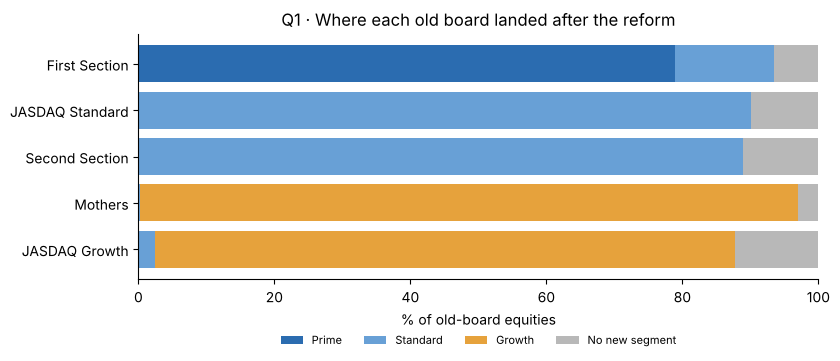

In [15]:
fig, ax = plt.subplots(figsize=(8.5,3.8))
order = q1.index[::-1]
left = np.zeros(len(order))
for col, color, lab in [('pct_prime','#2b6cb0','Prime'),('pct_standard','#68a0d6','Standard'),('pct_growth','#e6a23c','Growth'),('pct_no_segment','#b8b8b8','No new segment')]:
    vals = q1.loc[order, col].values
    ax.barh(order, vals, left=left, color=color, label=lab); left += vals
ax.set_xlim(0,100); ax.set_xlabel('% of old-board equities'); ax.set_title('Q1 · Where each old board landed after the reform')
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5,-0.18), frameon=False)
ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.savefig('docs/q1_migration.png', dpi=150); plt.show()

### Pregunta 2 — ¿Quiénes son las 3 mayores empresas de cada clase de tamaño TOPIX y cuánto pesan dentro de su clase?
Filtro: acciones con cotización y con clase de tamaño · Agregación: ranking con función de ventana (`ROW_NUMBER() OVER (PARTITION BY ...)`) y peso sobre el total de la clase.

In [16]:
q2_sql = '''
WITH base AS (
  SELECT c.size_rank, c.size_name, s.securities_code, s.name, q.close, q.market_cap,
         SUM(q.market_cap) OVER (PARTITION BY c.size_code)                         AS class_cap,
         ROW_NUMBER()      OVER (PARTITION BY c.size_code ORDER BY q.market_cap DESC) AS rk
  FROM security s
  JOIN quote q       ON q.securities_code = s.securities_code
  JOIN size_class c  ON c.size_code = s.size_code
  WHERE s.instrument_type = 'Equity'
)
SELECT size_name, rk, securities_code, name, close,
       ROUND(market_cap/1e9, 0)                    AS market_cap_bn_jpy,
       ROUND(100.0*market_cap/class_cap, 1)        AS pct_of_class
FROM base WHERE rk <= 3
ORDER BY size_rank, rk;
'''
q2 = pd.read_sql(q2_sql, con); q2

,size_name,rk,securities_code,name,close,market_cap_bn_jpy,pct_of_class
0,TOPIX Core30,1,7203,TOYOTA MOTOR CORPORATION,2105.5,34351.0,14.0
1,TOPIX Core30,2,6758,SONY GROUP CORPORATION,14475.0,18254.0,7.4
2,TOPIX Core30,3,6861,KEYENCE CORPORATION,72280.0,17579.0,7.2
3,TOPIX Large70,1,6902,DENSO CORPORATION,9529.0,7508.0,4.0
4,TOPIX Large70,2,4661,"ORIENTAL LAND CO.,LTD.",19395.0,7054.0,3.8
5,TOPIX Large70,3,9434,SoftBank Corp.,1454.5,6963.0,3.7
6,TOPIX Mid400,1,7182,"JAPAN POST BANK Co.,Ltd.",1055.0,3956.0,1.8
7,TOPIX Mid400,2,9613,NTT DATA CORPORATION,2466.0,3459.0,1.6
8,TOPIX Mid400,3,4307,"Nomura Research Institute,Ltd.",4935.0,3014.0,1.4
9,TOPIX Small 1,1,1881,NIPPO CORPORATION,3990.0,476.0,0.9


In [17]:
# Verificación en pandas
e = df[(df.instrument_type=='Equity') & df.has_quote & df.size_rank.notna()].copy()
e['mc'] = e.market_cap.astype(float)
e['pct'] = (100*e.mc/e.groupby('size_rank').mc.transform('sum')).round(1)
top = e.sort_values(['size_rank','mc'], ascending=[True,False]).groupby('size_rank').head(3)
assert list(top.securities_code) == list(q2.securities_code)
print('SQL y pandas coinciden')
cls = e.groupby('size_name', observed=True).agg(companies=('securities_code','count'), total_cap_trn=('mc', lambda s: round(s.sum()/1e12,1)),
         median_close=('close','median')).loc[['TOPIX Core30','TOPIX Large70','TOPIX Mid400','TOPIX Small 1','TOPIX Small 2']]
cls

SQL y pandas coinciden


,companies,total_cap_trn,median_close
size_name,,,
TOPIX Core30,30,245.3,5726.5
TOPIX Large70,70,187.3,3345.5
TOPIX Mid400,399,220.0,2520.0
TOPIX Small 1,499,50.5,1951.0
TOPIX Small 2,1182,31.1,1080.0


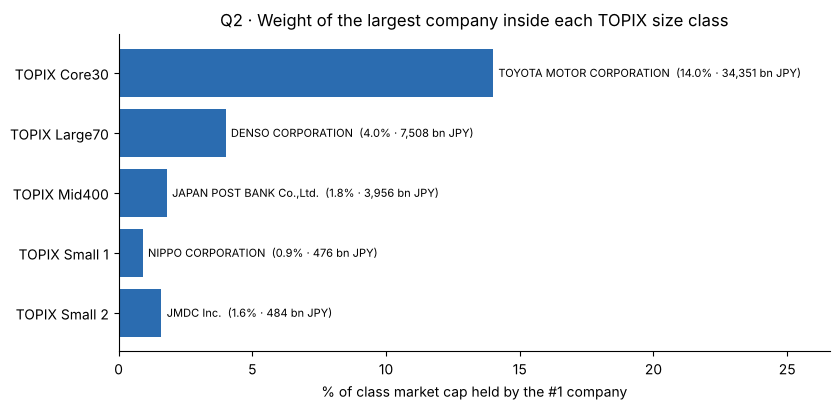

In [18]:
fig, ax = plt.subplots(figsize=(8.5,4.2))
d = q2[q2.rk==1]
ax.barh(d.size_name[::-1], d.pct_of_class[::-1], color='#2b6cb0')
for y,(n,p,m) in enumerate(zip(d.name[::-1], d.pct_of_class[::-1], d.market_cap_bn_jpy[::-1])):
    ax.text(p+0.2, y, f'{n}  ({p}% · {m:,.0f} bn JPY)', va='center', fontsize=8)
ax.set_xlim(0, d.pct_of_class.max()*1.9); ax.set_xlabel('% of class market cap held by the #1 company')
ax.set_title('Q2 · Weight of the largest company inside each TOPIX size class')
ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.savefig('docs/q2_class_leaders.png', dpi=150); plt.show()

## 5. Resumen de hallazgos

In [19]:
fs = q1.loc['First Section']
print(f"Q1: de {int(fs.companies)} acciones de la antigua First Section, {fs.pct_prime}% pasó a Prime, {fs.pct_standard}% a Standard, {fs.pct_growth}% a Growth y {fs.pct_no_segment}% no tiene segmento asignado.")
ms = q1.loc['Mothers']; print(f"    Mothers -> Growth: {ms.pct_growth}%.")
l1 = q2[q2.rk==1].set_index('size_name')
for k,r in l1.iterrows(): print(f"Q2: {k}: #1 {r['name']} ({r.pct_of_class}% de la clase)")
con.close()

Q1: de 2331 acciones de la antigua First Section, 78.9% pasó a Prime, 14.5% a Standard, 0.0% a Growth y 6.5% no tiene segmento asignado.
    Mothers -> Growth: 96.8%.
Q2: TOPIX Core30: #1 TOYOTA MOTOR CORPORATION (14.0% de la clase)
Q2: TOPIX Large70: #1 DENSO CORPORATION (4.0% de la clase)
Q2: TOPIX Mid400: #1 JAPAN POST BANK Co.,Ltd. (1.8% de la clase)
Q2: TOPIX Small 1: #1 NIPPO CORPORATION (0.9% de la clase)
Q2: TOPIX Small 2: #1 JMDC Inc. (1.6% de la clase)
